# Predicting Customer Churn with Logistic Regression and Decision Trees

**Dataset:** IBM Telco Customer Churn (7,043 customers of a fictional California provider).

Originally a group assignment for MCAI500 (Machine Learning) in the Master of Computer Science in Applied AI, by
Juan Davila, Alan Andre Guijarro Pomboza, Jonathan Hernandez Bautista and Jaime Williams Potes Pardo. This revised
version, maintained by Jonathan Hernandez, re-runs every result and addresses the instructor's feedback:

1. every figure quoted in the text now matches the notebook outputs (checked by `scripts/check_numbers.py`);
2. the model recommendation is backed by a cost-sensitivity analysis instead of assuming offers are cheap (Section 5.4);
3. the recommended Logistic Regression is explained directly (Section 5.6), and the decision-tree rules are presented
   only as patterns in the data (Section 5.7).

All four models use the same preprocessing, the same training/testing split and the same metrics.

## Setup
Same libraries as in class. `RANDOM_STATE = 42` makes every result reproducible, and the versions used are printed below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)   # show long text columns in full
plt.rcParams["figure.dpi"] = 150   # sharper figures

import sys, sklearn, matplotlib
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.12.10 | scikit-learn 1.7.2 | pandas 3.1.1 | numpy 2.5.5 | matplotlib 3.11.2 | seaborn 0.13.2


# Part 1. Problem Definition

- **Application domain:** telecommunications, customer retention.
- **Business problem:** IBM presents this dataset as a sample from a **fictional** California phone and internet provider, where 26.5% of
  customers churned in the quarter covered. As a descriptive figure, the customers labeled as churned paid **\$139,131 per month**
  (30.5% of all monthly charges). Keeping a customer is much cheaper than winning a new one, so the company wants to know
  **who is likely to leave** while there is still time to make them an offer.
- **Prediction objective:** binary classification: from a customer's profile, account and services, is the customer recorded as churned (1)
  or not (0)? The data are one historical sample without dates, so this experiment classifies the churn recorded in that sample (see Part 6
  for what a real deployment needs).
- **Target variable:** `Churn Value` (1 = the customer left).
- **Predictor variables (19):** demographics (gender, senior citizen, partner, dependents), account information (tenure, contract,
  paperless billing, payment method, monthly and total charges) and nine services (phone, multiple lines, internet, online security,
  online backup, device protection, tech support, streaming TV, streaming movies).
- **Why machine learning:** churn depends on many factors at once (contract, tenure, services, price), and they interact.
  Hand-written rules would miss many combinations. We have labeled historical data, so a supervised classifier can learn these
  patterns and give every customer a churn risk.
- **Main metric:** the **F1-score of the churn class**. The classes are imbalanced (Section 2.5), so accuracy alone is misleading,
  and both errors cost money: a missed churner means lost revenue, and a false alarm means a wasted offer. F1 guides tuning; when two
  models are close, the final choice depends on which error costs the business more (Part 5).

# Part 2. Exploratory Data Analysis
## 2.1 Load the data

In [2]:
from pathlib import Path

# Download the IBM Telco Customer Churn workbook (see data/README.md) and place it in the data/ folder.
candidates = [Path("../data/Telco_customer_churn.xlsx"), Path("../data/Assignment 1 Dataset.xlsx")]
DATA_PATH = next((path for path in candidates if path.exists()), candidates[0])
df = pd.read_excel(DATA_PATH)
print("Rows (customers):", df.shape[0])
print("Columns (variables):", df.shape[1])
df.head()

Rows (customers): 7043
Columns (variables): 33


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


**Interpretation:** the dataset has **7,043 rows and 33 columns**, one row per customer. Some columns (ID, location) are not useful
for prediction; they are handled in Part 3.

## 2.2 Data types and variable roles

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [4]:
target = "Churn Value"
numeric_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
categorical_cols = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service", "Online Security",
    "Online Backup", "Device Protection", "Tech Support", "Streaming TV",
    "Streaming Movies", "Contract", "Paperless Billing", "Payment Method",
]
# Identifiers, location columns and columns that already contain the answer (removed in Part 3).
excluded_cols = [col for col in df.columns if col not in numeric_cols + categorical_cols + [target]]

print(f"Predictors: {len(numeric_cols) + len(categorical_cols)} "
      f"({len(numeric_cols)} numerical, {len(categorical_cols)} categorical)")
print("Not used as predictors:", excluded_cols)

Predictors: 19 (3 numerical, 16 categorical)
Not used as predictors: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Reason']


**Interpretation:**
- Most columns are text (categorical). Tenure and Monthly Charges are numbers.
- **Total Charges is stored as text (`object`)** although it is an amount of money, which points to hidden non-numeric values (Section 2.3).
- We keep **19 predictors** (3 numerical, 16 categorical). The other 13 columns are identifiers, location details or columns that reveal the answer.

## 2.3 Missing values

In [5]:
missing = df.isna().sum()
print("Empty cells per column:")
print(missing[missing > 0])

# Total Charges was read as text, which suggests hidden blank values.
blank = df["Total Charges"].astype(str).str.strip() == ""
print("\nBlank Total Charges:", blank.sum())
print("Tenure of these customers (months):", df.loc[blank, "Tenure Months"].unique())

# Convert to numbers; the blanks become NaN and are filled with 0 in Part 3.2.
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

Empty cells per column:
Churn Reason    5174
dtype: int64

Blank Total Charges: 11
Tenure of these customers (months): [0]


**Interpretation:**
- Only **Churn Reason** has empty cells (5,174), because it is filled in only for customers who left. It is not a predictor.
- **Total Charges has 11 blank values**, and all of them belong to customers with **0 months of tenure**: new customers who have not
  been billed yet. Their true total is 0, so we fill them with 0 in Part 3 instead of guessing an average.

## 2.4 Summary statistics

In [6]:
summary = df[numeric_cols].describe().T
summary["skew"] = df[numeric_cols].skew()
display(summary.round(2))
display(df[categorical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max,skew
Tenure Months,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24
Monthly Charges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22
Total Charges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,0.96


,count,unique,top,freq
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361
Multiple Lines,7043,3,No,3390
Internet Service,7043,3,Fiber optic,3096
Online Security,7043,3,No,3498
Online Backup,7043,3,No,3088
Device Protection,7043,3,No,3095


**Interpretation:**
- Tenure goes from 0 to 72 months (median 29) and Monthly Charges from \$18 to \$119 (median \$70). **Total Charges is right-skewed**
  (skew 0.96): many recent customers have small totals.
- All values are in plausible ranges (no negative or impossible amounts).
- Most categorical variables have 2–3 categories. The most common contract is **month-to-month** (3,875 customers, 55%).
- The numerical columns use very different scales (months versus thousands of dollars), so they need scaling (Part 3).

## 2.5 Target class distribution

,customers,percentage
Churn Label,,
No,5174,73.5
Yes,1869,26.5


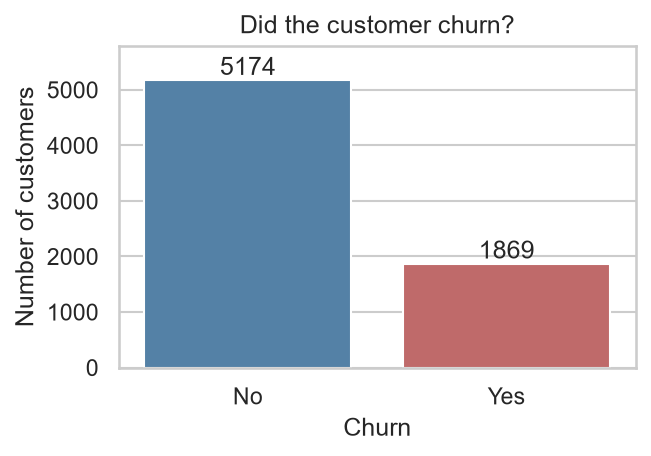

Accuracy of always predicting 'No churn': 0.735
Monthly charges of churners: $139,131 (30.5% of all monthly charges)


In [7]:
counts = df["Churn Label"].value_counts()
display(pd.DataFrame({"customers": counts, "percentage": (counts / len(df) * 100).round(1)}))

plt.figure(figsize=(4.5, 3.2))
ax = sns.countplot(data=df, x="Churn Label", hue="Churn Label", order=["No", "Yes"],
                   palette={"No": "steelblue", "Yes": "indianred"})
for container in ax.containers:
    ax.bar_label(container)
ax.set_ylim(0, counts.max() * 1.12)
plt.title("Did the customer churn?")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# A model that always predicts "No churn" already reaches this accuracy.
print(f"Accuracy of always predicting 'No churn': {counts['No'] / len(df):.3f}")

# Business size of the problem: monthly charges paid by the customers who left.
lost = df.loc[df[target] == 1, "Monthly Charges"].sum()
print(f"Monthly charges of churners: ${lost:,.0f} ({lost / df['Monthly Charges'].sum():.1%} of all monthly charges)")

**Interpretation:**
- 5,174 customers stayed (73.5%) and 1,869 churned (26.5%): the dataset is **imbalanced** (about 3 to 1).
- A useless model that always answers "no churn" would already score **73.5% accuracy** while catching nobody. That is why we judge models
  on precision, recall and F1 of the churn class, use stratified splits, and test `class_weight="balanced"` during tuning.
- The customers who left paid **\$139,131 per month (30.5% of all monthly charges)**, which shows what is at stake.

## 2.6 Numerical features and churn

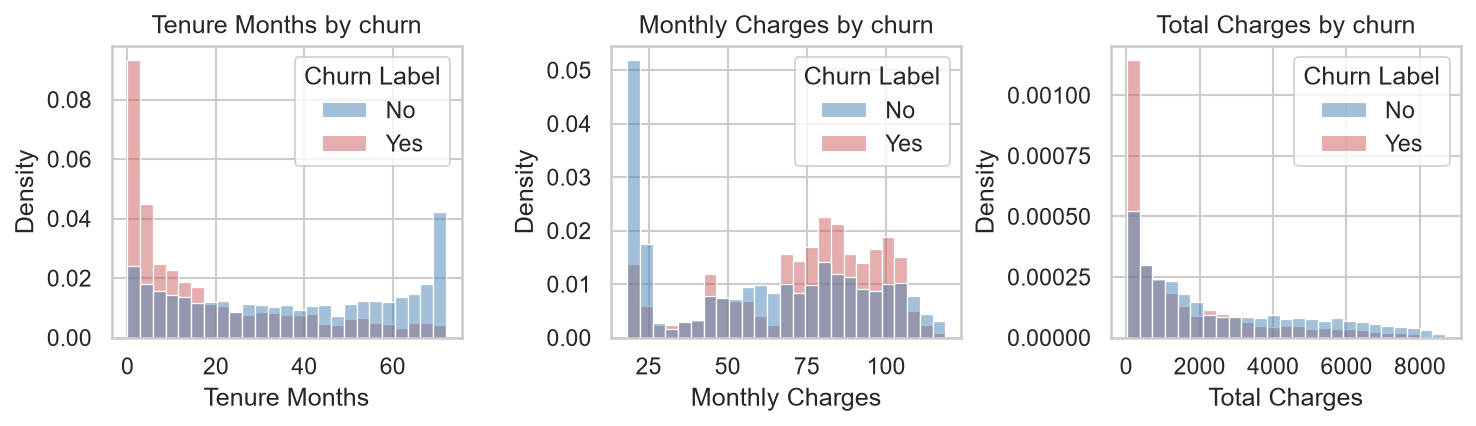

Churn rate, tenure <= 12 months: 47.4 %
Churn rate, tenure > 48 months:  9.5 %


customers  churners  churn_rate
Contract       Tenure                                      
Month-to-month 0-12 months       1994      1024        51.4
               13+ months        1881       631        33.5
One year       0-12 months        124        13        10.5
               13+ months        1349       153        11.3
Two year       0-12 months         68         0         0.0
               13+ months        1627        48         3.0

,Tenure Months,Monthly Charges,Total Charges
Churn Label,,,
No,38.0,64.4,1683.6
Yes,10.0,79.6,703.6


In [8]:
# Densities put both classes on the same scale, although there are almost three times more non-churners.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.0))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, hue="Churn Label", hue_order=["No", "Yes"], bins=25, stat="density",
                 common_norm=False, palette={"No": "steelblue", "Yes": "indianred"}, ax=ax)
    ax.set_title(f"{col} by churn")
    ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

print("Churn rate, tenure <= 12 months:", round(df.loc[df["Tenure Months"] <= 12, target].mean() * 100, 1), "%")
print("Churn rate, tenure > 48 months: ", round(df.loc[df["Tenure Months"] > 48, target].mean() * 100, 1), "%")

# Churn by contract and tenure group, with the number of customers behind each rate.
contract_tenure = (df.assign(Tenure=np.where(df["Tenure Months"] <= 12, "0-12 months", "13+ months"))
                     .groupby(["Contract", "Tenure"])[target].agg(customers="count", churners="sum", churn_rate="mean"))
contract_tenure["churn_rate"] = (contract_tenure["churn_rate"] * 100).round(1)
display(contract_tenure)
df.groupby("Churn Label")[numeric_cols].median().round(1)

**Interpretation:**
- Churners are much newer customers: **median tenure 10 months versus 38** for those who stayed. Churn is concentrated in the first year
  (47.4% churn up to 12 months versus 9.5% after 48 months).
- Churners pay **more per month** (median \$79.6 versus \$64.4) but less in total, because they have been customers for a shorter time.
- Contract and tenure work together. Among month-to-month customers, churn was **51.4%** in the first 12 months (1,024 of 1,994) and 33.5% after
  that (631 of 1,881). On one-year contracts the two groups are similar (10.5% vs 11.3%), and none of the 68 two-year customers in their first
  year churned. A decision tree can capture this kind of interaction.

## 2.7 Categorical features and churn

Contract {'Month-to-month': 42.7, 'One year': 11.3, 'Two year': 2.8}
Internet Service {'Fiber optic': 41.9, 'DSL': 19.0, 'No': 7.4}
Payment Method {'Electronic check': 45.3, 'Mailed check': 19.1, 'Bank transfer (automatic)': 16.7, 'Credit card (automatic)': 15.2}
Tech Support {'No': 41.6, 'Yes': 15.2, 'No internet service': 7.4}


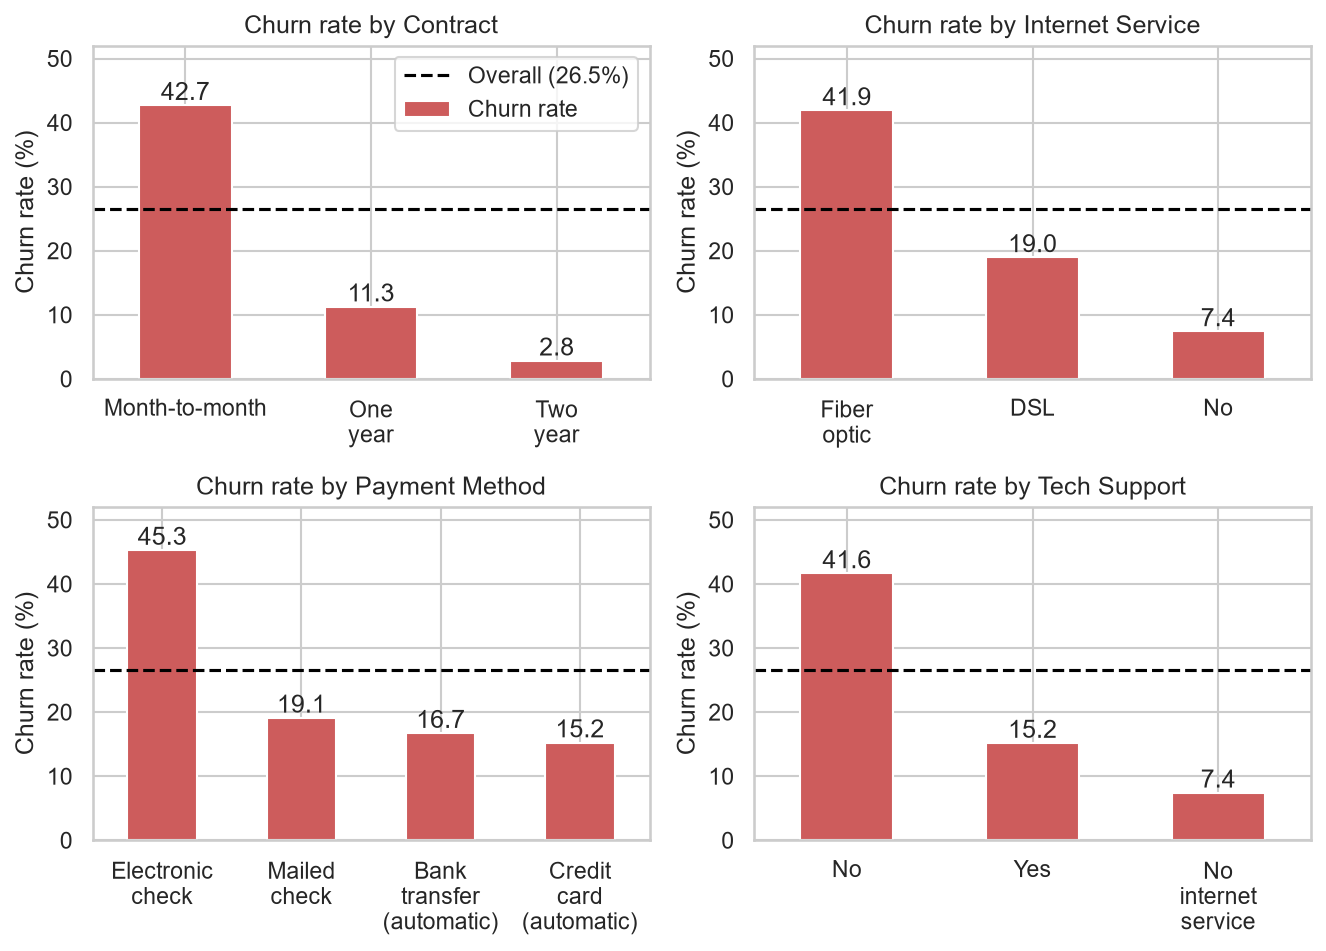

Senior Citizen {'No': 23.6, 'Yes': 41.7}
Gender {'Female': 26.9, 'Male': 26.2}


In [9]:
# Churn rate of each category; the dashed line is the overall churn rate.
overall_rate = df[target].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(9, 6.5))
for ax, col in zip(axes.ravel(), ["Contract", "Internet Service", "Payment Method", "Tech Support"]):
    rate = (df.groupby(col)[target].mean().sort_values(ascending=False) * 100).rename("Churn rate")
    print(col, rate.round(1).to_dict())
    rate.index = rate.index.str.replace(" ", "\n")  # one word per line so long labels do not overlap
    rate.plot(kind="bar", ax=ax, color="indianred", rot=0)
    ax.axhline(overall_rate, color="black", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
    ax.bar_label(ax.containers[0], fmt="%.1f")
    ax.set_ylim(0, 52)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

# Two more variables, as a table.
for col in ["Senior Citizen", "Gender"]:
    print(col, (df.groupby(col)[target].mean() * 100).round(1).to_dict())

**Interpretation:**
- **Contract** shows the strongest pattern: **42.7%** churn for month-to-month, 11.3% for one-year and only 2.8% for two-year contracts.
- **Fiber optic** customers churn 41.9% versus 19.0% for DSL, which may point to price or service-quality issues.
- **Electronic check** payers churn 45.3%, about three times more than automatic payments (15–17%).
- Customers **without tech support** churn 41.6% versus 15.2% with it.
- Senior citizens churn more (41.7% versus 23.6%), while **gender makes no difference** (26.9% versus 26.2%).

## 2.8 Correlation analysis

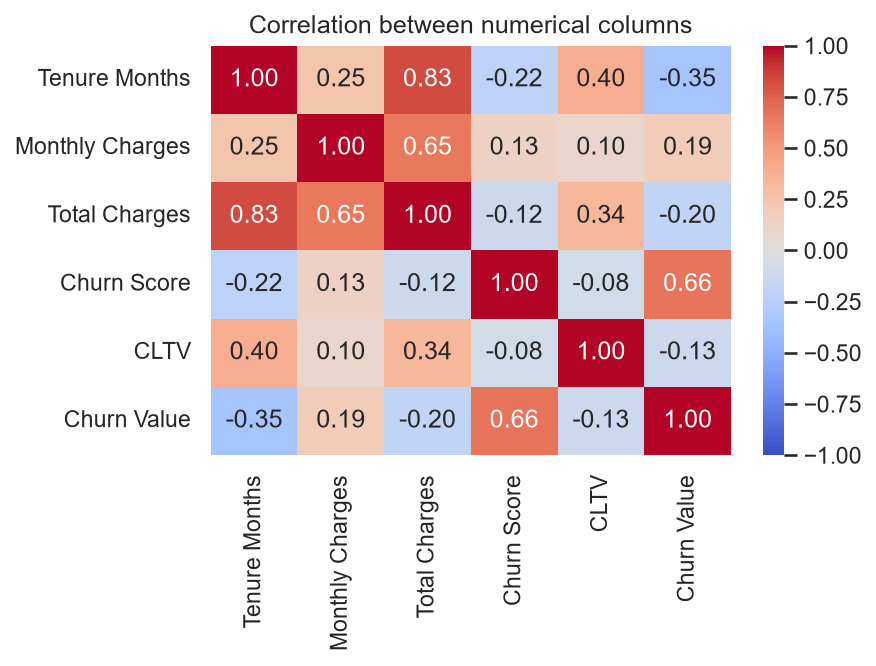

Churn Score range of customers who churned: 65 - 100


Tenure Months     -0.35
Total Charges     -0.20
CLTV              -0.13
Monthly Charges    0.19
Churn Score        0.66
Name: Churn Value, dtype: float64

In [10]:
corr = df[numeric_cols + ["Churn Score", "CLTV", target]].corr()
plt.figure(figsize=(6, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numerical columns")
plt.tight_layout()
plt.show()

print("Churn Score range of customers who churned:",
      df.loc[df[target] == 1, "Churn Score"].min(), "-", df.loc[df[target] == 1, "Churn Score"].max())
corr[target].drop(target).sort_values().round(2)

**Interpretation:**
- **Tenure** has the strongest link with churn among the real predictors (r = −0.35): long-standing customers rarely leave. Monthly Charges
  is weakly positive (0.19).
- **Tenure and Total Charges are strongly correlated (r = 0.83)**, because the total is roughly tenure × monthly charge. We keep both,
  since they are not identical, but this overlap means single coefficients should be read with care.
- **Churn Score correlates 0.66 with churn**, far more than any real predictor, and every churner has a score of at least 65. It is IBM's
  own churn prediction, so using it would be **data leakage**: the model would copy an existing answer. It is removed in Part 3.

### Key EDA findings
1. The target is imbalanced (26.5% churn), so we use F1, precision and recall, stratified splits and class weights.
2. The strongest churn signals are a **month-to-month contract, short tenure, fiber optic internet, electronic check payment and no tech support**.
3. Data quality is good: 11 hidden blanks with a clear explanation, plausible values, and no duplicates (checked in Part 3).
4. Columns that repeat the target, are IBM model outputs or are known only after churn (Churn Label, Churn Score, CLTV, Churn Reason) must be removed.

# Part 3. Data Preprocessing
Every step below is applied in exactly the same way for all four models.

## 3.1 Duplicate records

In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate CustomerID values:", df["CustomerID"].duplicated().sum())

Duplicate rows: 0
Duplicate CustomerID values: 0


**Interpretation:** there are no duplicate rows and no repeated customer IDs, so nothing needs to be removed.

## 3.2 Remove identifier, irrelevant and leakage variables, and fill unbilled Total Charges

| Removed columns | Reason |
|---|---|
| CustomerID, Count | Identifier and a constant (always 1) |
| Country, State | One value for everyone, so no information |
| City, Zip Code, Lat Long, Latitude, Longitude | Over a thousand distinct places; the model would memorize locations instead of behavior |
| Churn Label | The target written as text |
| Churn Score, CLTV, Churn Reason | IBM's own model outputs, or information known only after the customer left (**leakage**) |

We also replace **"No internet service"** with "No" in the six add-on columns (Online Security, Online Backup, Device Protection,
Tech Support, Streaming TV, Streaming Movies) and **"No phone service"** with "No" in Multiple Lines. Whether a customer has internet or
phone at all is already in Internet Service and Phone Service, so keeping these values would create duplicate columns.

**Missing values:** the 11 blank Total Charges are set to **0**, but only where Tenure Months is 0 (customers not billed yet); no other value
is touched. Like the column removal, this is a fixed rule that learns nothing from the data, so it is applied once before the split.

In [12]:
print("Distinct values:", {col: df[col].nunique() for col in ["Count", "Country", "State", "City", "Zip Code"]})

# "No internet service" / "No phone service" repeat what Internet Service and Phone Service already say.
X = df[numeric_cols + categorical_cols].replace({"No internet service": "No", "No phone service": "No"})

# Blank Total Charges belong to customers with 0 months of tenure (not billed yet): set exactly those to 0.
unbilled = (X["Tenure Months"] == 0) & X["Total Charges"].isna()
X.loc[unbilled, "Total Charges"] = 0
y = df[target]
print("Total Charges set to 0 (tenure 0, not billed yet):", unbilled.sum())
print("Missing values left in X:", X.isna().sum().sum())
print("Removed columns:", excluded_cols)
print("X:", X.shape, "| y:", y.shape)

Distinct values: {'Count': 1, 'Country': 1, 'State': 1, 'City': 1129, 'Zip Code': 1652}
Total Charges set to 0 (tenure 0, not billed yet): 11
Missing values left in X: 0
Removed columns: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Reason']
X: (7043, 19) | y: (7043,)


**Interpretation:** Count, Country and State have a single value, and City and Zip Code have more than 1,100 values each. After removing
these columns, **19 predictors** remain. Exactly the 11 unbilled customers were filled, and no missing values are left.

## 3.3 Training/testing split
We use 80% of the data for training and 20% for testing, **stratified** so that both sets keep the 26.5% churn rate. The test set is used only
once, in Part 5. Hyperparameters are chosen with 5-fold stratified cross-validation **inside the training set**.

In [13]:
# Stratify so that both sets keep the 26.5% churn rate; the test set is not touched until Part 5.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print(f"Churn rate - training: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

# The same 5 stratified folds are used for every cross-validation step.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training rows: 5634 | Test rows: 1409
Churn rate - training: 0.265 | test: 0.265


## 3.4 Encoding and scaling in one pipeline
- **Encoding:** most categorical variables have no natural order (nominal), so we use **one-hot encoding**; for Contract it also avoids
  assuming equal steps between month-to-month, one-year and two-year. Yes/No variables keep a
  single column (`drop="if_binary"`).
- **Scaling:** `StandardScaler` (mean 0, standard deviation 1) puts tenure (0–72) and total charges (up to \$8,685) on the same scale.
  Logistic Regression needs this so that regularization treats all features fairly. Trees do not need it, but the assignment asks for the
  same preprocessing for every model.
- Everything sits in a `Pipeline` with a `ColumnTransformer`. It is fitted on the training data only (and, during cross-validation, on the
  training folds only), so **no information leaks** from the test set.

In [14]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    # drop="if_binary" keeps a single column for Yes/No variables.
    ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_cols),
], verbose_feature_names_out=False)

# Fitted on the training set only, then applied to the test set (no information leaks from the test set).
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Prepared training set:", X_train_prepared.shape)
print("Prepared test set:", X_test_prepared.shape)
print("Model features:", list(feature_names))

Prepared training set: (5634, 26)
Prepared test set: (1409, 26)
Model features: ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Gender_Male', 'Senior Citizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'Phone Service_Yes', 'Multiple Lines_Yes', 'Internet Service_DSL', 'Internet Service_Fiber optic', 'Internet Service_No', 'Online Security_Yes', 'Online Backup_Yes', 'Device Protection_Yes', 'Tech Support_Yes', 'Streaming TV_Yes', 'Streaming Movies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'Paperless Billing_Yes', 'Payment Method_Bank transfer (automatic)', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check']


**Interpretation:** the training set has 5,634 customers and the test set 1,409, both with 26.5% churn. After encoding, the 19 predictors
become **26 model features**:
- 3 scaled numerical features: Tenure Months, Monthly Charges, Total Charges;
- 13 single 0/1 columns for the two-value predictors (Gender, Senior Citizen, Partner, Dependents, Phone Service, Multiple Lines,
  Paperless Billing and the six add-on services);
- 10 columns for the levels of Internet Service (3), Contract (3) and Payment Method (4).

# Part 4. Model Development and Optimization

- **Logistic Regression** estimates the probability of churn from a weighted sum of the features. It is simple and fast, and gives a churn
  probability for every customer. Main hyperparameters: `C` (the inverse of the regularization strength: a smaller C means simpler weights) and
  `class_weight`.
- **Decision Tree** splits customers with yes/no questions (for example, "month-to-month contract?"). It captures interactions and is easy to
  read, but without limits it keeps splitting until it memorizes the training data. Main hyperparameters: `max_depth`, `min_samples_leaf`,
  `criterion` and `class_weight`.

Models are compared with **5-fold cross-validation on the training set**; `cv_scores()` returns the mean training and validation scores.
The test-set predictions of all four models are made together in Part 5, after both grid searches, so the test set plays no role in tuning.

In [15]:
def cv_scores(model):
    """Mean 5-fold cross-validation scores on the training set."""
    s = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    return pd.Series({
        "train_accuracy": s["train_accuracy"].mean(), "val_accuracy": s["test_accuracy"].mean(),
        "val_precision": s["test_precision"].mean(), "val_recall": s["test_recall"].mean(),
        "train_f1": s["train_f1"].mean(), "val_f1": s["test_f1"].mean(), "val_roc_auc": s["test_roc_auc"].mean(),
    }).round(3)

## 4.1 Model 1 - Logistic Regression (Baseline)
**Why:** it is the standard, interpretable starting point for a yes/no prediction. We use the default settings (C = 1, no class weights).

In [16]:
log_reg_baseline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),  # default C=1.0
])
log_reg_baseline.fit(X_train, y_train)   # training

cv_scores(log_reg_baseline)

train_accuracy    0.814
val_accuracy      0.812
val_precision     0.666
val_recall        0.581
train_f1          0.626
val_f1            0.620
val_roc_auc       0.859
dtype: float64

## 4.2 Model 2 - Decision Tree (Baseline)
**Why:** a tree can capture interactions such as contract × tenure (Section 2.6) and produces readable rules.
We use the default settings (no depth limit).

In [17]:
tree_baseline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),  # no depth limit
])
tree_baseline.fit(X_train, y_train)

print("Tree depth:", tree_baseline.named_steps["model"].get_depth())
print("Number of leaves:", tree_baseline.named_steps["model"].get_n_leaves())
cv_scores(tree_baseline)

Tree depth: 30
Number of leaves: 1051


train_accuracy    0.998
val_accuracy      0.733
val_precision     0.496
val_recall        0.501
train_f1          0.997
val_f1            0.498
val_roc_auc       0.659
dtype: float64

**Interpretation of the baselines:**
- **Logistic Regression:** training accuracy (0.814) and validation accuracy (0.812) are almost equal, so there is **no overfitting**.
  But recall is only **0.581**: it misses about 4 in 10 churners, because with imbalanced data the model leans toward "no churn".
- **Decision Tree:** it grows to **depth 30 with 1,051 leaves**, about one leaf per five customers. Training accuracy 0.998 versus
  validation 0.733 shows that it **memorizes the training data (overfitting)**. Its validation F1 (0.498) is the worst.

## 4.3 Understanding the hyperparameters (one at a time)
Before the grid search, we change **one hyperparameter at a time** while everything else stays at its default, to see what each one does.

,train_accuracy,val_accuracy,val_precision,val_recall,train_f1,val_f1,val_roc_auc
C,,,,,,,
0.001,0.761,0.760,0.844,0.116,0.212,0.204,0.844
0.010,0.809,0.808,0.687,0.506,0.585,0.582,0.853
0.100,0.813,0.812,0.673,0.565,0.618,0.614,0.858
1.000,0.814,0.812,0.666,0.581,0.626,0.620,0.859
10.000,0.814,0.812,0.667,0.585,0.627,0.623,0.859
100.000,0.814,0.812,0.665,0.585,0.627,0.622,0.859


,train_accuracy,val_accuracy,val_precision,val_recall,train_f1,val_f1,val_roc_auc
class_weight,,,,,,,
None,0.814,0.812,0.666,0.581,0.626,0.62,0.859
balanced,0.762,0.758,0.529,0.810,0.646,0.64,0.859


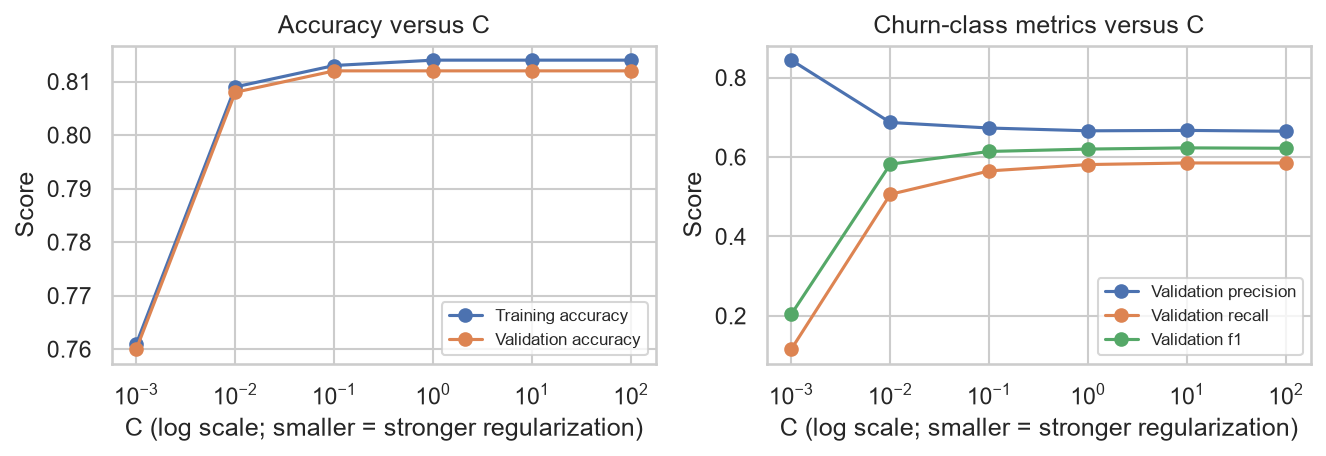

In [18]:
# C: one value at a time, everything else at its default.
c_values = [0.001, 0.01, 0.1, 1, 10, 100]
c_study = pd.DataFrame({c: cv_scores(clone(log_reg_baseline).set_params(model__C=c)) for c in c_values}).T
c_study.index.name = "C"
display(c_study)

# class_weight: None (default) versus "balanced", at the default C=1.
weight_study = pd.DataFrame({str(w): cv_scores(clone(log_reg_baseline).set_params(model__class_weight=w))
                             for w in [None, "balanced"]}).T
weight_study.index.name = "class_weight"
display(weight_study)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(c_values, c_study["train_accuracy"], marker="o", label="Training accuracy")
axes[0].plot(c_values, c_study["val_accuracy"], marker="o", label="Validation accuracy")
axes[0].set_title("Accuracy versus C")
for metric in ["precision", "recall", "f1"]:
    axes[1].plot(c_values, c_study[f"val_{metric}"], marker="o", label=f"Validation {metric}")
axes[1].set_title("Churn-class metrics versus C")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale; smaller = stronger regularization)")
    ax.set_ylabel("Score")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation (Logistic Regression):**
- **C:** a very small C (0.001) shrinks the weights so much that the model rarely predicts churn (recall 0.116, F1 0.204). From C = 0.1
  upward the scores hardly change (F1 0.614–0.623), and training and validation accuracy stay within 0.002 of each other for every C. With 5,634 customers and
  only 26 features, Logistic Regression does not overfit, so **C is not the main lever** here.
- **class_weight="balanced":** churners get about 2.8 times more weight during training. Recall jumps from **0.581 to 0.810** and F1 rises
  from 0.620 to 0.640, while precision falls from 0.666 to 0.529 and accuracy from 0.812 to 0.758. This is the central trade-off of the
  project: **catching more churners also means more false alarms.**

,train_accuracy,val_accuracy,val_precision,val_recall,train_f1,val_f1,val_roc_auc
max_depth,,,,,,,
2,0.765,0.765,0.552,0.629,0.587,0.587,0.791
3,0.792,0.789,0.699,0.364,0.486,0.478,0.820
4,0.795,0.787,0.680,0.388,0.508,0.490,0.837
5,0.804,0.790,0.602,0.619,0.637,0.610,0.843
6,0.815,0.796,0.645,0.520,0.624,0.575,0.841
8,0.843,0.783,0.600,0.551,0.690,0.572,0.813
10,0.884,0.760,0.550,0.538,0.777,0.543,0.762
15,0.971,0.739,0.509,0.512,0.945,0.510,0.692
None,0.998,0.733,0.496,0.501,0.997,0.498,0.659


,train_accuracy,val_accuracy,val_precision,val_recall,train_f1,val_f1,val_roc_auc
min_samples_leaf,,,,,,,
1,0.998,0.733,0.496,0.501,0.997,0.498,0.659
5,0.893,0.765,0.564,0.506,0.788,0.533,0.765
10,0.859,0.777,0.593,0.514,0.713,0.550,0.807
20,0.835,0.782,0.610,0.493,0.658,0.545,0.822
50,0.815,0.789,0.626,0.512,0.616,0.563,0.840
100,0.805,0.791,0.639,0.497,0.588,0.557,0.838
200,0.797,0.788,0.649,0.448,0.555,0.529,0.826


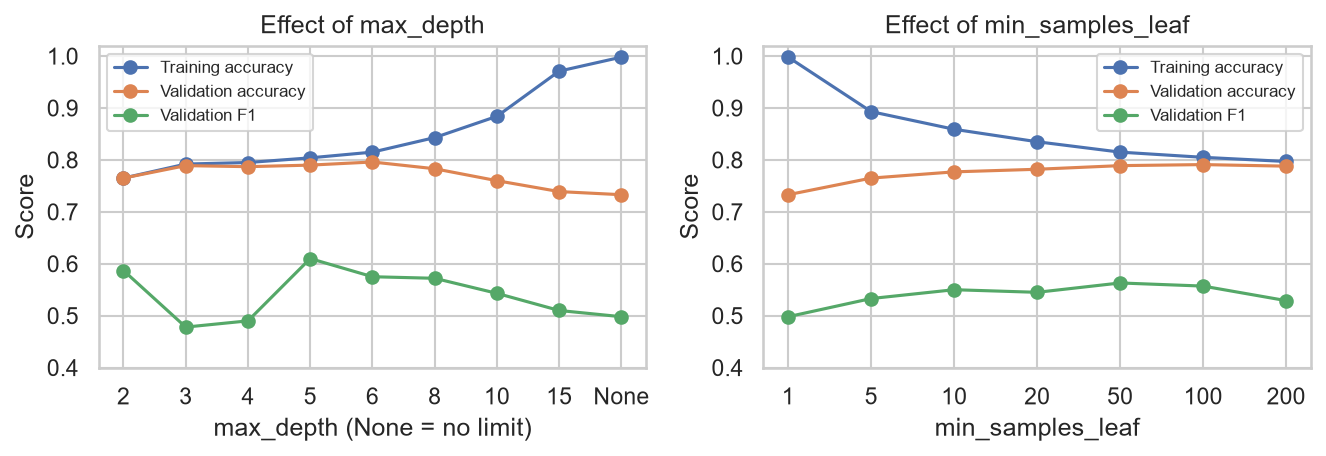

In [19]:
# max_depth and min_samples_leaf: one at a time, everything else at its default.
depth_values = [2, 3, 4, 5, 6, 8, 10, 15, None]
depth_study = pd.DataFrame({str(d): cv_scores(clone(tree_baseline).set_params(model__max_depth=d))
                            for d in depth_values}).T
depth_study.index.name = "max_depth"
display(depth_study)

leaf_values = [1, 5, 10, 20, 50, 100, 200]
leaf_study = pd.DataFrame({n: cv_scores(clone(tree_baseline).set_params(model__min_samples_leaf=n))
                           for n in leaf_values}).T
leaf_study.index.name = "min_samples_leaf"
display(leaf_study)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, study, label in [(axes[0], depth_study, "max_depth (None = no limit)"),
                         (axes[1], leaf_study, "min_samples_leaf")]:
    x = study.index.astype(str)
    ax.plot(x, study["train_accuracy"], marker="o", label="Training accuracy")
    ax.plot(x, study["val_accuracy"], marker="o", label="Validation accuracy")
    ax.plot(x, study["val_f1"], marker="o", label="Validation F1")
    ax.set_xlabel(label)
    ax.set_ylabel("Score")
    ax.set_ylim(0.4, 1.02)
    ax.legend(fontsize=8)
axes[0].set_title("Effect of max_depth")
axes[1].set_title("Effect of min_samples_leaf")
plt.tight_layout()
plt.show()

**Interpretation (Decision Tree):**
- **max_depth:** training accuracy keeps rising with depth (0.765 → 0.998), while validation accuracy peaks at depth 5–6 (0.790–0.796) and then
  falls (0.733 with no limit). This is the classic overfitting curve. The best validation F1 in this study is at depth 5 (0.610).
- **min_samples_leaf:** asking for more customers per leaf has a similar effect. The gap between training and validation accuracy shrinks from
  about 0.27 (1 customer) to about 0.03 (50 customers), and validation F1 improves from 0.498 to 0.563.
- Shallow trees (depth 3–4) have high precision but low recall: they only flag the most obvious churners. This is why the grid search also
  tries class weights.

## 4.4 Model 3 - Optimized Logistic Regression
**Why:** Model 1 already generalized well; tuning should mainly fix its low recall.
**Grid:** `C` (6 values) × `class_weight` (2 values) = 12 combinations, with 5-fold stratified cross-validation.
**Selection score:** F1 of the churn class, which balances precision and recall (accuracy would reward ignoring churners).
`GridSearchCV` then refits the best combination on the whole training set.

In [20]:
lr_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}
# 12 combinations x 5 folds; F1 of the churn class decides.
lr_search = GridSearchCV(log_reg_baseline, lr_grid, scoring="f1", cv=cv, return_train_score=True)
lr_search.fit(X_train, y_train)
print("Best parameters:", lr_search.best_params_)
print("Best cross-validated F1:", round(lr_search.best_score_, 3))

lr_results = pd.DataFrame(lr_search.cv_results_)
lr_results["class_weight"] = lr_results["param_model__class_weight"].fillna("None")  # keep the None column visible
lr_results.pivot_table(index="param_model__C", columns="class_weight", values="mean_test_score").round(3)

Best parameters: {'model__C': 100, 'model__class_weight': 'balanced'}
Best cross-validated F1: 0.641


class_weight,None,balanced
param_model__C,,
0.001,0.204,0.636
0.010,0.582,0.639
0.100,0.614,0.639
1.000,0.620,0.640
10.000,0.623,0.640
100.000,0.622,0.641


**Interpretation:**
- Best combination: **C = 100 with class_weight = "balanced"** (cross-validated F1 = 0.641).
- With balanced weights, every C from 0.01 to 100 scores between 0.639 and 0.641. That difference is too small to matter, so the gain over
  the baseline comes from **class weighting, not from C**, as the one-at-a-time study suggested.

In [21]:
log_reg_optimized = lr_search.best_estimator_   # refitted on the whole training set
print("Model 3:", log_reg_optimized.named_steps["model"])

Model 3: LogisticRegression(C=100, class_weight='balanced', max_iter=1000,
                   random_state=42)


## 4.5 Model 4 - Optimized Decision Tree
**Why:** Model 2 overfitted badly, so the tree must be limited.
**Grid:** `max_depth` (7) × `min_samples_leaf` (5) × `criterion` (gini or entropy) × `class_weight` (2) = 140 combinations,
with the same folds and the same F1 score.

In [22]:
tree_grid = {
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 10, 20, 50, 100],
    "model__criterion": ["gini", "entropy"],
    "model__class_weight": [None, "balanced"],
}
# 140 combinations x 5 folds.
tree_search = GridSearchCV(tree_baseline, tree_grid, scoring="f1", cv=cv, return_train_score=True)
tree_search.fit(X_train, y_train)
print("Best parameters:", tree_search.best_params_)
print("Best cross-validated F1:", round(tree_search.best_score_, 3))

tree_results = pd.DataFrame(tree_search.cv_results_).sort_values("rank_test_score", kind="stable")
tree_results[["param_model__max_depth", "param_model__min_samples_leaf", "param_model__criterion",
              "param_model__class_weight", "mean_train_score", "mean_test_score", "std_test_score"]].head(5).round(3)

Best parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 4, 'model__min_samples_leaf': 1}
Best cross-validated F1: 0.63


,param_model__max_depth,param_model__min_samples_leaf,param_model__criterion,param_model__class_weight,mean_train_score,mean_test_score,std_test_score
110,4,1,entropy,balanced,0.642,0.63,0.014
111,4,10,entropy,balanced,0.642,0.63,0.014
112,4,20,entropy,balanced,0.642,0.63,0.014
113,4,50,entropy,balanced,0.642,0.63,0.014
115,5,1,entropy,balanced,0.651,0.63,0.011


**Interpretation:**
- Best combination: **max_depth = 4, criterion = entropy, class_weight = "balanced"** (cross-validated F1 = 0.630). At depth 4,
  min_samples_leaf barely matters: the tested values from 1 to 50 give very similar mean CV F1 scores (0.630 when rounded).
- Training F1 (0.642) and validation F1 (0.630) are close, so the tuned tree **no longer overfits**.

In [23]:
tree_optimized = tree_search.best_estimator_   # refitted on the whole training set
print("Tree depth:", tree_optimized.named_steps["model"].get_depth())
print("Number of leaves:", tree_optimized.named_steps["model"].get_n_leaves())

Tree depth: 4
Number of leaves: 13


# Part 5. Model Evaluation and Comparison
All four models are evaluated **once** on the same 1,409 test customers with the same metrics. Precision, recall and F1 refer to the
churn class (1).

## 5.1 Test-set predictions, training/testing accuracy and classification reports

In [24]:
models = {
    "Model 1: Logistic Regression (Baseline)": log_reg_baseline,
    "Model 2: Decision Tree (Baseline)": tree_baseline,
    "Model 3: Logistic Regression (Optimized)": log_reg_optimized,
    "Model 4: Decision Tree (Optimized)": tree_optimized,
}
rows, test_predictions = [], {}
for name, model in models.items():
    y_pred = model.predict(X_test)        # test-set predictions, made once, after all tuning is finished
    test_predictions[name] = y_pred
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, y_pred)
    print("=" * 62)
    print(name)
    print(f"Training accuracy: {train_acc:.3f} | Testing accuracy: {test_acc:.3f}")
    print(classification_report(y_test, y_pred, target_names=["No churn (0)", "Churn (1)"], digits=3))
    rows.append({"Model": name, "Train Accuracy": train_acc, "Test Accuracy": test_acc,
                 "Precision": precision_score(y_test, y_pred), "Recall": recall_score(y_test, y_pred),
                 "F1-score": f1_score(y_test, y_pred),
                 "ROC AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})

Model 1: Logistic Regression (Baseline)
Training accuracy: 0.813 | Testing accuracy: 0.804
              precision    recall  f1-score   support

No churn (0)      0.852     0.887     0.869      1035
   Churn (1)      0.648     0.575     0.609       374

    accuracy                          0.804      1409
   macro avg      0.750     0.731     0.739      1409
weighted avg      0.798     0.804     0.800      1409

Model 2: Decision Tree (Baseline)
Training accuracy: 0.998 | Testing accuracy: 0.744
              precision    recall  f1-score   support

No churn (0)      0.828     0.822     0.825      1035
   Churn (1)      0.517     0.527     0.522       374

    accuracy                          0.744      1409
   macro avg      0.672     0.674     0.673      1409
weighted avg      0.745     0.744     0.745      1409

Model 3: Logistic Regression (Optimized)
Training accuracy: 0.762 | Testing accuracy: 0.740
              precision    recall  f1-score   support

No churn (0)      0.901

**Interpretation:**
- **Model 1** has the best accuracy (0.804) and precision (0.648), but recall is only 0.575.
- **Model 2** confirms the overfitting: 0.998 training versus 0.744 testing accuracy, and the lowest F1 (0.522).
- **Model 3** has the **highest recall (0.778)**, but precision is 0.507, so about one in two flagged customers really churns. Its accuracy
  drops to 0.740 because it flags many more customers.
- **Model 4** has the **best F1 (0.630)**, with precision 0.554 and recall 0.730, and nearly equal training and testing accuracy (0.782 versus 0.772).
- Every model predicts the "No churn" class well (F1 0.80–0.87). The hard class is churn.

## 5.2 Confusion matrices

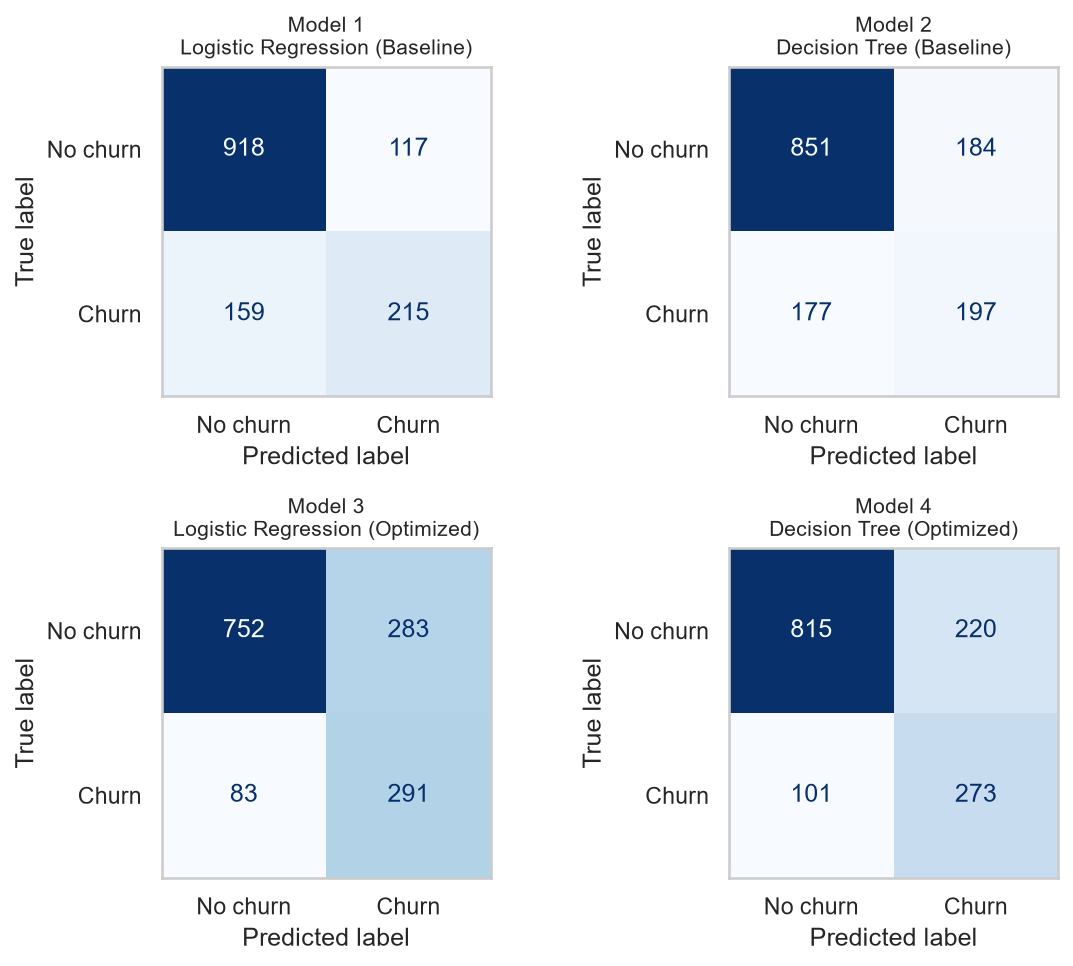

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6.6))
for ax, (name, y_pred) in zip(axes.ravel(), test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name.replace(": ", "\n"), fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

**Interpretation (out of 374 churners in the test set):**
- **Model 1** finds 215 churners and misses 159, with 117 false alarms.
- **Model 2** finds 197 and misses 177, with 184 false alarms.
- **Model 3** finds **291** and misses only 83, but raises **283** false alarms.
- **Model 4** finds 273 and misses 101, with 220 false alarms.

If a missed churner (lost revenue) costs more than an unnecessary offer, as is common in retention, the optimized models are more useful
than Model 1 even though their accuracy is lower. How much more it costs decides between Model 3 (more churners caught) and Model 4 (fewer false alarms);
Section 5.4 puts numbers on that choice.

## 5.3 Comparison table

In [26]:
comparison = pd.DataFrame(rows).set_index("Model")
comparison["Comments"] = [
    "Highest accuracy and precision, but misses 43% of churners",
    "Overfits (train 0.998); lowest recall, F1 and AUC",
    "Highest recall (catches 78% of churners); about half of its alerts are false (recommended)",
    "Best test F1; 63 fewer false alarms but 18 fewer churners caught than Model 3",
]
comparison.round(3)

,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC AUC,Comments
Model,,,,,,,
Model 1: Logistic Regression (Baseline),0.813,0.804,0.648,0.575,0.609,0.849,"Highest accuracy and precision, but misses 43% of churners"
Model 2: Decision Tree (Baseline),0.998,0.744,0.517,0.527,0.522,0.674,"Overfits (train 0.998); lowest recall, F1 and AUC"
Model 3: Logistic Regression (Optimized),0.762,0.740,0.507,0.778,0.614,0.848,Highest recall (catches 78% of churners); about half of its alerts are false (recommended)
Model 4: Decision Tree (Optimized),0.782,0.772,0.554,0.730,0.630,0.841,Best test F1; 63 fewer false alarms but 18 fewer churners caught than Model 3


**Discussion:**
- **Which model performed best?** It depends on where we look. On the **test set**, Model 4 has the best F1 (0.630 vs 0.614) and the best accuracy
  of the two optimized models (0.772). In the **cross-validation used for tuning**, Model 3 had the higher mean F1 (0.641 vs 0.630). Model 3 also has
  the best recall (0.778), and Model 1 the best accuracy (0.804) and precision.
- **Which model generalized better?** Models 1 and 4 have the smallest differences between training and testing accuracy (about 0.01),
  Model 3 is close behind (about 0.02), and Model 2 overfits (0.254).
- **Did optimization improve performance?** For the tree, clearly: F1 rose from 0.522 to 0.630 and the train–test gap fell from 0.254 to 0.010, so
  tuning considerably reduced the overfitting. For Logistic Regression, recall rose from 0.575 to 0.778 and F1 improved slightly (0.609 → 0.614),
  while precision fell from 0.648 to 0.507: tuning shifted the balance toward catching churners.
- **Trade-offs:** among the well-fitted models, higher recall came with lower precision and accuracy (Model 1 versus Model 3). For the tree, tuning
  raised all three at once because it removed the overfitting.
- **Recommendation:** **pilot Model 3 (optimized Logistic Regression), and set its cut-off from the measured costs.**
  The goal is to find customers who may leave and offer them a promotion. With its default cut-off, Model 3 catches **18 more churners**
  than Model 4 (291 vs 273) at the cost of **63 more false alarms** (283 vs 220): it contacts 81 more customers (574 vs 493), about 4.5
  extra offers for each extra churner reached. That is only worth it when a kept churner is worth more than about 4.5 offers (k > 4.50,
  Section 5.4). The dataset has no offer costs or retention rates, so this cannot be assumed: under the illustrative assumptions in
  Section 5.4 (k = 3.6), Model 4's operating point would be better. Model 3 is still the better candidate because it can reach that
  operating point too: restricted to its 493 highest-risk customers, it finds 272 churners, practically the same as Model 4's 273. It also
  has the highest cross-validated F1 (0.641) and gives almost every customer a different risk score (Section 5.5), so its cut-off can
  follow the k that a pilot measures. Its own drivers are explained in Section 5.6. Model 4 remains a simple alternative whose rules are
  easy to show to managers (Section 5.7).

## 5.4 Cost-sensitivity analysis: when is each model worth more?

The original recommendation assumed that retention offers are cheap compared with a lost customer. Instead of
assuming it, this section measures how the choice depends on the business numbers.

Suppose the company sends an offer to every customer a model flags. Each offer costs **c**. A contacted churner is
kept with probability **r**, and a kept customer is worth **V** in future revenue. The net value of the campaign is
`r·V·(churners contacted) − c·(customers contacted)`. Dividing by **c**, it depends on a single number,
**k = r·V / c**: how many offers one contacted churner is worth.

,churners_contacted,customers_contacted
Model 1: Logistic Regression (Baseline),215,332
Model 2: Decision Tree (Baseline),197,381
Model 3: Logistic Regression (Optimized),291,574
Model 4: Decision Tree (Optimized),273,493


Model 3 is worth more than Model 4 when k > 4.50
Model 3 is worth more than Model 1 when k > 3.18
Model 4 is worth more than Model 1 when k > 2.78
Model 1 only pays off when k > 1.54 (one over its precision)
Model 3 only pays off when k > 1.97 (one over its precision)
Model 4 only pays off when k > 1.81 (one over its precision)


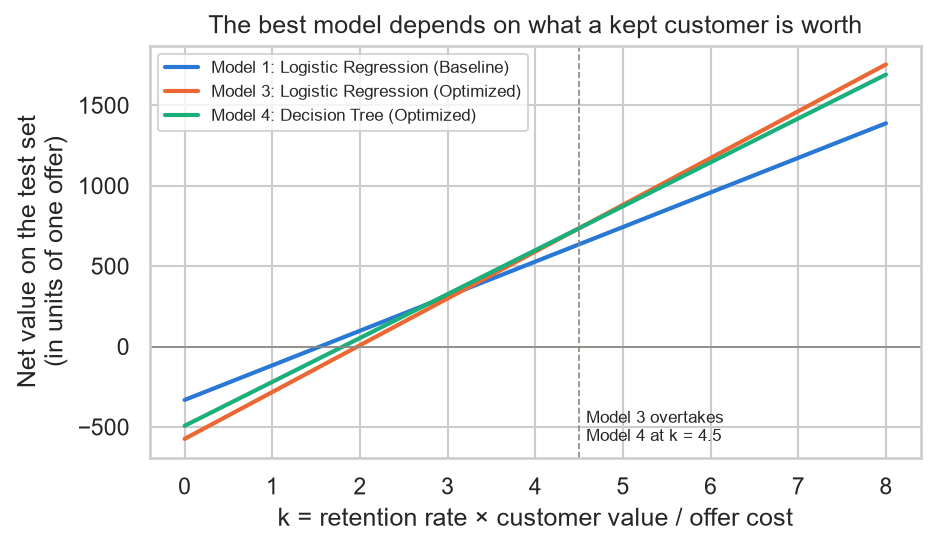

Median monthly charge of churners: $79.65
Example assumptions give k = 3.6
Model 3 contacting only its top 493 customers reaches 272 churners (Model 4: 273)


In [27]:
campaign = pd.DataFrame({
    name: {"churners_contacted": int(((y_pred == 1) & (y_test == 1)).sum()),
           "customers_contacted": int((y_pred == 1).sum())}
    for name, y_pred in test_predictions.items()
}).T
display(campaign)

names = list(models)
m1, m3, m4 = names[0], names[2], names[3]


def break_even(better_recall, other):
    """k above which the model that reaches more churners is worth more than the other one."""
    extra_churners = campaign.loc[better_recall, "churners_contacted"] - campaign.loc[other, "churners_contacted"]
    extra_contacts = campaign.loc[better_recall, "customers_contacted"] - campaign.loc[other, "customers_contacted"]
    return extra_contacts / extra_churners


k_3_vs_4 = break_even(m3, m4)
k_3_vs_1 = break_even(m3, m1)
k_4_vs_1 = break_even(m4, m1)
print(f"Model 3 is worth more than Model 4 when k > {k_3_vs_4:.2f}")
print(f"Model 3 is worth more than Model 1 when k > {k_3_vs_1:.2f}")
print(f"Model 4 is worth more than Model 1 when k > {k_4_vs_1:.2f}")
for name in [m1, m3, m4]:
    profitable = campaign.loc[name, "customers_contacted"] / campaign.loc[name, "churners_contacted"]
    print(f"{name.split(':')[0]} only pays off when k > {profitable:.2f} (one over its precision)")

k_values = np.linspace(0, 8, 161)
plt.figure(figsize=(6.4, 3.8))
for name, color in [(m1, "#2a78d6"), (m3, "#eb6834"), (m4, "#1baf7a")]:
    value = k_values * campaign.loc[name, "churners_contacted"] - campaign.loc[name, "customers_contacted"]
    plt.plot(k_values, value, color=color, linewidth=2, label=name.split(":")[0] + ":" + name.split(":")[1])
plt.axhline(0, color="#898781", linewidth=0.8)
plt.axvline(k_3_vs_4, color="#898781", linestyle="--", linewidth=0.8)
plt.text(k_3_vs_4 + 0.08, plt.ylim()[0] * 0.85, f"Model 3 overtakes\nModel 4 at k = {k_3_vs_4:.1f}", fontsize=8)
plt.xlabel("k = retention rate × customer value / offer cost")
plt.ylabel("Net value on the test set\n(in units of one offer)")
plt.title("The best model depends on what a kept customer is worth")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# An illustration, not a finding: one month free as the offer, a kept customer stays 12 more months,
# and the offer convinces 30% of contacted churners.
median_charge = df.loc[df[target] == 1, "Monthly Charges"].median()
example_k = 0.30 * (12 * median_charge) / median_charge
print(f"Median monthly charge of churners: ${median_charge:.2f}")
print(f"Example assumptions give k = {example_k:.1f}")

# Model 3 ranks customers finely, so its cut-off can be moved. Same number of contacts as Model 4:
model3_scores = log_reg_optimized.predict_proba(X_test)[:, 1]
budget = int(campaign.loc[m4, "customers_contacted"])
top = np.argsort(-model3_scores)[:budget]
print(f"Model 3 contacting only its top {budget} customers reaches {int(np.asarray(y_test)[top].sum())} churners "
      f"(Model 4: {campaign.loc[m4, 'churners_contacted']})")

**Interpretation:**
- Each line is one model's net value as k grows, and the best model changes with k:
  - below **k = 1.54**, no campaign pays off: even Model 1, the most precise, spends more on offers than it saves;
  - from 1.54 to **2.78**, Model 1 is worth the most, because it wastes the fewest offers;
  - from 2.78 to **4.50**, Model 4 is worth the most;
  - above **4.50**, Model 3 is worth the most: each extra churner it reaches over Model 4 costs 4.5 extra offers (81 / 18).
- **What is k in practice?** If the offer is one month free, k is the retention rate times the number of extra months a kept customer
  stays, because the monthly charge cancels out. With the example assumptions (30% retention, 12 more months) k = 3.6, which would favor
  **Model 4**. Model 3 would need, for example, 30% retention and more than 15 extra months, or 50% retention and more than 9. These are
  illustrations: the dataset has no offer costs or retention rates, so the assumption that offers are cheap enough cannot be confirmed
  from the data. A pilot campaign should measure it.
- **Model 3's cut-off can be moved.** Restricted to its 493 highest-risk customers (as many contacts as Model 4), Model 3 reaches 272
  churners, practically the same as Model 4's 273. So Model 3 is not tied to its high-recall setting: once k is known, its threshold can be
  set to the matching operating point, which Model 4's 13 distinct scores allow only coarsely.
- **Caveats:** the break-even values rest on small differences (18 churners between Models 3 and 4) in a single test split, so they are
  rough. The analysis also assumes the same retention rate for every contacted churner and treats an offer to a loyal customer as pure cost.

## 5.5 ROC curves
The ROC curve shows recall against the false-positive rate for every possible threshold. The area under it (AUC) measures how well a model
**ranks** churners above non-churners.

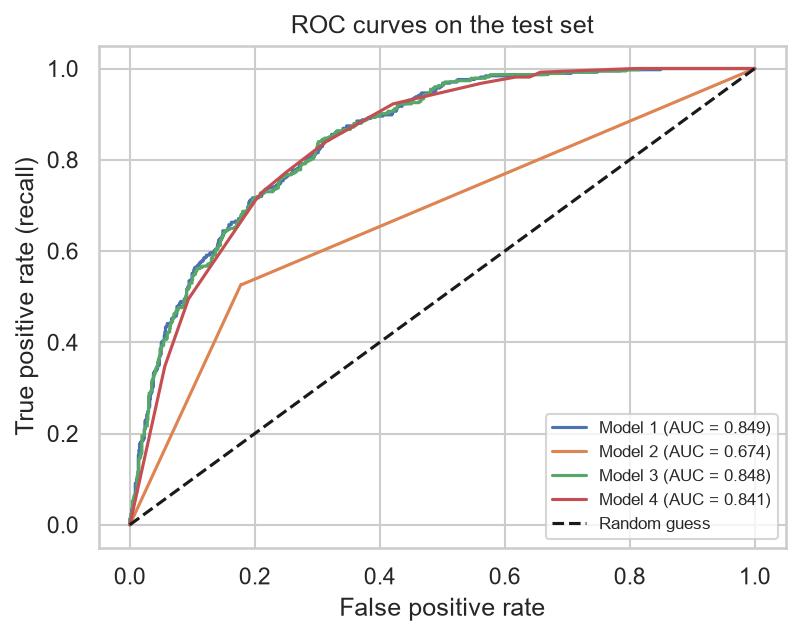

Distinct churn scores given by Model 3: 1407
Distinct churn scores given by Model 4: 13


In [28]:
plt.figure(figsize=(5.5, 4.4))
for name, model in models.items():
    scores = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name.split(':')[0]} (AUC = {roc_auc_score(y_test, scores):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Distinct churn scores given by Model 3:", len(np.unique(log_reg_optimized.predict_proba(X_test)[:, 1].round(6))))
print("Distinct churn scores given by Model 4:", len(np.unique(tree_optimized.predict_proba(X_test)[:, 1])))

**Interpretation:**
- The two Logistic Regressions rank customers slightly better (AUC 0.849 and 0.848) than the optimized tree (0.841). The baseline tree is far behind (0.674).
- Class weighting did not change the ranking of Logistic Regression (0.849 versus 0.848); it mostly moved the cut-off between "churn" and "no churn".
- The optimized tree gives only **13 different scores** (one per leaf), so its ranking is coarse, while Model 3 gives 1,407 different scores to the
  1,409 test customers. If the company wanted to contact exactly the top 100 riskiest customers, Logistic Regression would rank them more finely.

## 5.6 Explaining the recommended model (Model 3)

The tree rules in Section 5.7 explain Model 4's predictions, not Model 3's. To explain Model 3 itself, we use three
complementary views:

- **Odds ratios** of its coefficients: how the odds of churn change per unit of each feature. Numerical features are
  standardized, so their unit is one standard deviation. Overlapping features (tenure and total charges, r = 0.83)
  make single coefficients less reliable, so this view is checked against the next two.
- **Permutation importance** on the test set: how much Model 3's ROC AUC drops when one original predictor is shuffled.
  It measures each predictor as a whole, so overlapping one-hot columns do not split its importance.
- **A surrogate tree** trained to imitate Model 3's predictions, with its **fidelity** (agreement with Model 3) measured
  on the test set. Its rules describe Model 3's behavior only as far as that agreement goes.

,coefficient,odds_ratio
Internet Service_No,-3.010,0.049
Monthly Charges,-2.045,0.129
Dependents_Yes,-1.638,0.194
Contract_Two year,-1.277,0.279
Tenure Months,-1.231,0.292
Multiple Lines_Yes,0.586,1.796
Phone Service_Yes,0.815,2.258
Streaming TV_Yes,0.882,2.416
Streaming Movies_Yes,0.904,2.469
Internet Service_Fiber optic,1.814,6.135


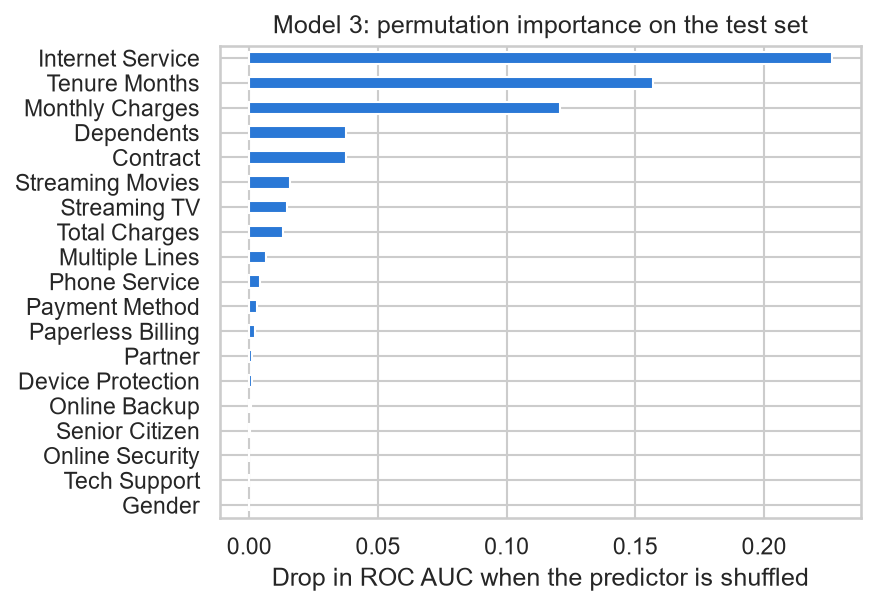

Internet Service    0.226
Tenure Months       0.157
Monthly Charges     0.121
Dependents          0.038
Contract            0.037
Streaming Movies    0.016
dtype: float64

Surrogate agrees with Model 3 on 92.1% of test customers
|--- Contract_Month-to-month <= 0.50
|   |--- Payment Method_Electronic check <= 0.50
|   |   |--- Internet Service_Fiber optic <= 0.50
|   |   |   |--- class: 0
|   |   |--- Internet Service_Fiber optic >  0.50
|   |   |   |--- class: 0
|   |--- Payment Method_Electronic check >  0.50
|   |   |--- Contract_One year <= 0.50
|   |   |   |--- class: 0
|   |   |--- Contract_One year >  0.50
|   |   |   |--- class: 0
|--- Contract_Month-to-month >  0.50
|   |--- Dependents_Yes <= 0.50
|   |   |--- Internet Service_No <= 0.50
|   |   |   |--- class: 1
|   |   |--- Internet Service_No >  0.50
|   |   |   |--- class: 0
|   |--- Dependents_Yes >  0.50
|   |   |--- Internet Service_Fiber optic <= 0.50
|   |   |   |--- class: 0
|   |   |--- Internet Service_Fiber optic >

In [29]:
from sklearn.inspection import permutation_importance
from sklearn.tree import export_text

# 1. Odds ratios of Model 3's coefficients.
coefficients = pd.Series(log_reg_optimized.named_steps["model"].coef_[0], index=feature_names)
odds = pd.DataFrame({"coefficient": coefficients, "odds_ratio": np.exp(coefficients)}).sort_values("coefficient")
display(pd.concat([odds.head(5), odds.tail(5)]).round(3))

# 2. Permutation importance of each original predictor (drop in test ROC AUC).
permutation = permutation_importance(log_reg_optimized, X_test, y_test, scoring="roc_auc",
                                     n_repeats=20, random_state=RANDOM_STATE)
importance = pd.Series(permutation.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(6, 4.2))
importance.plot(kind="barh", color="#2a78d6")
plt.title("Model 3: permutation importance on the test set")
plt.xlabel("Drop in ROC AUC when the predictor is shuffled")
plt.tight_layout()
plt.show()
print(importance.sort_values(ascending=False).head(6).round(3))

# 3. A depth-3 surrogate tree that imitates Model 3, and how often it agrees with it.
surrogate = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
surrogate.fit(X_train_prepared, log_reg_optimized.predict(X_train))
fidelity = accuracy_score(log_reg_optimized.predict(X_test), surrogate.predict(X_test_prepared))
print(f"\nSurrogate agrees with Model 3 on {fidelity:.1%} of test customers")
print(export_text(surrogate, feature_names=list(feature_names), show_weights=False))

# Numerical thresholds are standardized; convert them back to real units.
scaler = preprocessor.named_transformers_["numeric"]
for i, col in enumerate(numeric_cols):
    for z in sorted(surrogate.tree_.threshold[surrogate.tree_.feature == i]):
        print(f"{col} <= {z:.2f} (standardized) means {col} <= {scaler.mean_[i] + z * scaler.scale_[i]:.1f}")

**Interpretation:**
- **What Model 3 relies on most (permutation importance):** the type of internet service (the test ROC AUC drops by 0.226 when it is
  shuffled), tenure (0.157) and monthly charges (0.121). Dependents (0.038), contract (0.037) and streaming movies (0.016) follow far
  behind. Contract matters much less here than in Model 4, likely because its information overlaps with tenure (customers on long contracts
  have usually been customers longer): when one of them is shuffled, the model still gets most of that information from the other.
- **Direction of the effects (coefficients):** fiber optic internet raises the odds of churn the most (odds ratio 6.135) and having no
  internet service lowers them the most (0.049). Dependents (0.194), a two-year contract (0.279) and longer tenure (0.292 per standard
  deviation) also lower them. These directions match the EDA. Every level of Internet Service, Contract and Payment Method has its own
  column, so those coefficients are best compared with each other within a predictor. Monthly Charges has a negative coefficient (odds ratio
  0.129) although churners pay more on average: the bill is largely determined by the services (fiber, streaming, phone lines), whose
  coefficients are positive, so this coefficient only describes the bill *with those services held fixed*. This is why no coefficient is
  read on its own.
- **A readable approximation (surrogate tree):** Model 3 flags month-to-month customers without dependents who have internet service, and
  predicts that everyone else stays. This rule agrees with Model 3 on 92.1% of the test customers; for the rest, Model 3's finer
  combination of features decides.
- **Same drivers as Model 4?** Largely yes: contract type, internet type, tenure and dependents matter in both. So the rules in Section 5.7
  describe patterns that Model 3 also uses, but they are not an explanation of Model 3's predictions. This section is.

## 5.7 Patterns in the data: rules of the optimized tree (Model 4)
These rules explain **Model 4's** predictions, not the recommended Model 3's. They are useful because they describe the
main churn patterns in plain words, and Section 5.6 checks whether Model 3 relies on the same drivers.

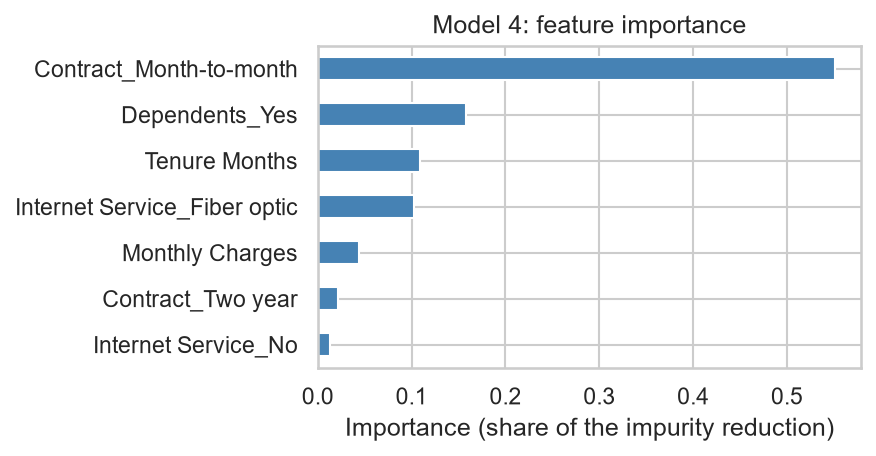

Model 4 feature importance: {'Contract_Month-to-month': 0.55, 'Dependents_Yes': 0.16, 'Tenure Months': 0.11, 'Internet Service_Fiber optic': 0.1}


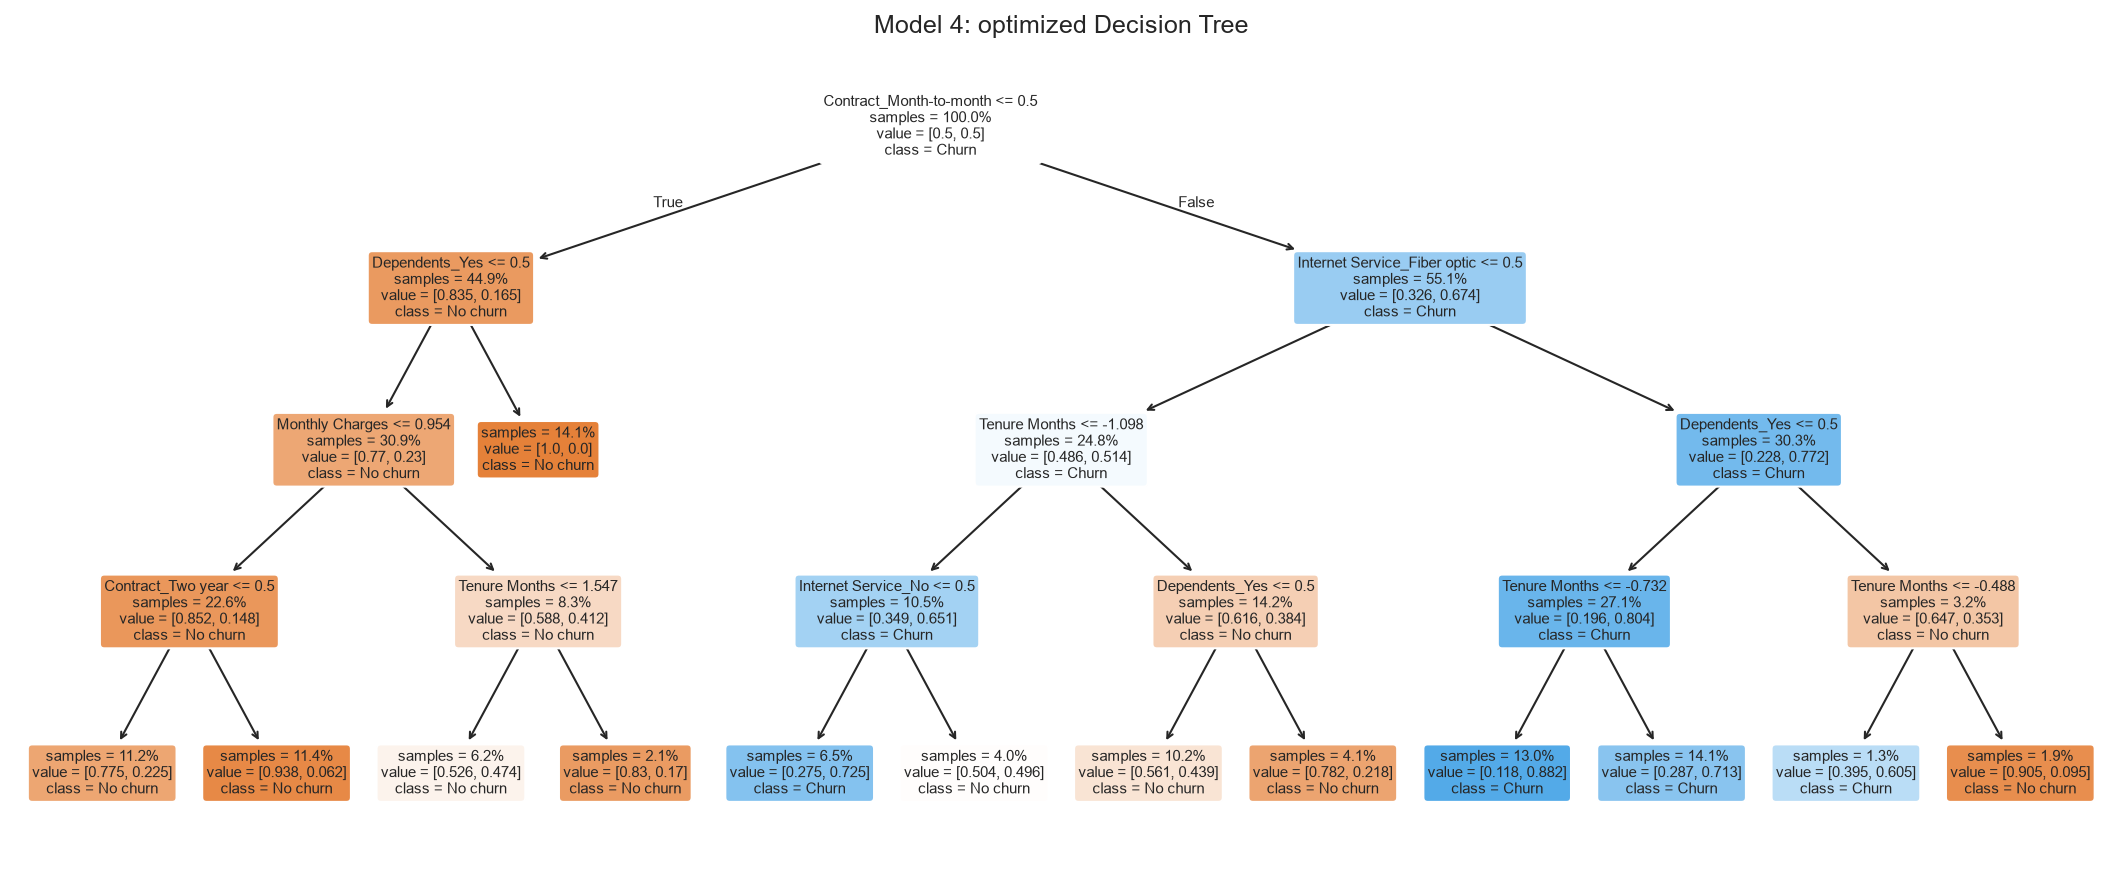

Tenure Months <= -1.10 (standardized) means Tenure Months <= 5.5
Tenure Months <= -0.73 (standardized) means Tenure Months <= 14.5
Tenure Months <= -0.49 (standardized) means Tenure Months <= 20.5
Tenure Months <= 1.55 (standardized) means Tenure Months <= 70.5
Monthly Charges <= 0.95 (standardized) means Monthly Charges <= 93.7

Churn rate by Dependents: {'No': 32.6, 'Yes': 6.5}


In [30]:
importances = pd.Series(tree_optimized.named_steps["model"].feature_importances_, index=feature_names)
importances = importances[importances > 0].sort_values()
plt.figure(figsize=(6, 3.2))
importances.plot(kind="barh", color="steelblue")
plt.title("Model 4: feature importance")
plt.xlabel("Importance (share of the impurity reduction)")
plt.tight_layout()
plt.show()
print("Model 4 feature importance:", importances.sort_values(ascending=False).head(4).round(2).to_dict())

# The tree itself (13 leaves). Blue boxes predict churn, orange boxes predict no churn.
plt.figure(figsize=(18, 7))
plot_tree(tree_optimized.named_steps["model"], feature_names=list(feature_names), class_names=["No churn", "Churn"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=7)
plt.title("Model 4: optimized Decision Tree")
plt.show()

# Numerical thresholds are standardized (z = (value - mean) / std), so convert them back to real units.
scaler = tree_optimized.named_steps["preprocessor"].named_transformers_["numeric"]
tree_ = tree_optimized.named_steps["model"].tree_
for i, col in enumerate(numeric_cols):          # the numerical columns are the first features
    for z in sorted(tree_.threshold[tree_.feature == i]):
        print(f"{col} <= {z:.2f} (standardized) means {col} <= {scaler.mean_[i] + z * scaler.scale_[i]:.1f}")

print("\nChurn rate by Dependents:", (df.groupby("Dependents")[target].mean() * 100).round(1).to_dict())

**Interpretation:**
- **Contract** is by far the most important feature (importance 0.55, the first split), followed by Dependents (0.16), tenure (0.11) and fiber optic internet (0.10).
- In plain words, the tree says:
  1. Customers on a **one- or two-year contract** are predicted to stay.
  2. **Month-to-month + fiber optic** customers are predicted to churn, except those with dependents who have been customers for 21 months or more.
  3. **Month-to-month without fiber** customers are predicted to churn only with **5 months of tenure or less**, and only if they have internet (DSL).
- These rules match the EDA. They suggest a hypothesis that a pilot could test: offering longer contracts to new month-to-month customers,
  especially fiber customers, may reduce churn.
- **Dependents** carries a lot of weight (6.5% churn with dependents versus 32.6% without). Family status is personal information, so its use
  should be reviewed for fairness before deployment.

# Part 6. Discussion and Conclusion
- **Recommended model:** Model 3, the optimized Logistic Regression (C = 100, balanced class weights), as the model to pilot, with its cut-off set from the measured value of k (Section 5.4).
  Test recall 0.778, F1 0.614, precision 0.507, accuracy 0.740; cross-validated F1 0.641.
- **Strengths:** it catches the most churners (291 of 374), generalizes well (gap about 0.02), is fast, and ranks customers finely (AUC 0.848), so the
  number of contacts can match the budget. Model 4's three rules (Section 5.7) describe the main churn patterns, and Section 5.6 shows
  that Model 3 relies on the same drivers.
- **Limitations:** IBM presents the data as a sample from a fictional company; it is one historical snapshot without dates, so we cannot check that
  every predictor was measured before the customer left; a single 80/20 test split; about half of Model 3's alerts are false alarms
  (precision 0.507), so with its default cut-off it beats Model 4 only if a kept churner is worth more than about 4.5 offers (Section 5.4); and the optimized models are close (test F1 0.630 vs 0.614 for the tree, but cross-validated
  F1 0.641 vs 0.630 for Logistic Regression).
- **Did the optimized models beat their baselines?** The tree did, clearly: limiting its depth considerably reduced the overfitting (gap 0.254 → 0.010).
  For Logistic Regression, recall rose (0.575 → 0.778) and F1 improved slightly (0.609 → 0.614), while precision fell (0.648 → 0.507). It was not
  overfitting to begin with, so the class weights mainly moved its balance toward catching churners.
- **Possible improvements:** measure k with a pilot and set Model 3's threshold from it, try ensembles such as Random Forest, add behavioral data
  (complaints, usage, support calls), and evaluate with real campaign costs.
- **Lessons learned:** accuracy is misleading on imbalanced data; limiting tree complexity matters more than any other setting; class weights
  were the biggest lever for Logistic Regression; keeping preprocessing inside a pipeline prevents leakage; and when two models have almost
  the same F1, the cost of each kind of mistake decides, so a recommendation should state its break-even point instead of assuming it.
- **Before deployment:** fix a cut-off date and a prediction horizon (for example, churn in the next three months), build the predictors from data
  available on that date, validate on a later cohort of customers, and run a pilot campaign (which can also test whether longer contracts reduce churn).
  Then monitor performance and data drift, retrain periodically, and check fairness (for example, retrain Model 3 without Dependents and compare recall by group).

## References
- IBM. (2019). *Telco customer churn* [Data set]. Kaggle. https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset
- Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning* (2nd ed.). Springer.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.